In [98]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable, fill_table_v2
from PlateDict import wellMap

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [3]:
from scipy.stats import pearsonr, spearmanr

In [4]:
from matplotlib_venn import venn3_unweighted

In [5]:
import glob

In [6]:
orf_mapping = GetOrfMapping()
orf_to_symbol = dict(zip(orf_mapping.orf_id, orf_mapping.symbol))

# xp  data

In [7]:
plate_d = {'Plate1':'1A_1B',
'Plate2':'1A_Frag2',
'Plate3':'Frag1_1B',
'Plate4':'2A_2B',
'Plate5':'2A_Frag2',
'Plate6':'Frag1_2B',
'Plate7':'GFP_1A_1B',
'Plate8':'GFP_1A_Frag2',
'Plate9':'GFP_Frag1_1B',
'Plate10':'GFP_2A_2B',
'Plate11':'GFP_2A_Frag2',
'Plate12':'GFP_Frag1_2B'}

In [8]:
res = {}
for elem in glob.glob('20210223_yN2H_PRS/*'):
    if 'Plate' in elem:

        plate = elem.split('_')[3]
        plate_details = plate_d[plate]
        
        pla = 1 if '1A' in plate_details or '1B' in plate_details else 2
        
        test = 'AB' if 'A' in plate_details and 'B' in plate_details else 'AF2' if 'A' in plate_details  else 'BF1'
        vector = 'GFP' if 'GFP' in plate_details else 'old'
        
        xp = f'{test}_{vector}'
        
        if xp not in  res:
            res[xp] =  dict()

        df = pd.read_excel(elem, skiprows=10, skipfooter=35)
        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
        
        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (pla,f'{l}{str(i+1).zfill(2)}')
                res[xp][key] = value
                


In [14]:
plate_d

{'Plate1': '1A_1B',
 'Plate2': '1A_Frag2',
 'Plate3': 'Frag1_1B',
 'Plate4': '2A_2B',
 'Plate5': '2A_Frag2',
 'Plate6': 'Frag1_2B',
 'Plate7': 'GFP_1A_1B',
 'Plate8': 'GFP_1A_Frag2',
 'Plate9': 'GFP_Frag1_1B',
 'Plate10': 'GFP_2A_2B',
 'Plate11': 'GFP_2A_Frag2',
 'Plate12': 'GFP_Frag1_2B'}

In [18]:
res = {}
for elem in glob.glob('data/*'):
    if 'Plate' in elem:

        plate = elem.split('_')[1]
        plate_details = plate_d[plate]
        
        pla = 1 if '1A' in plate_details or '1B' in plate_details else 2
        
        test = 'AB' if 'A' in plate_details and 'B' in plate_details else 'AF2' if 'A' in plate_details  else 'BF1'
        vector = 'GFP' if 'GFP' in plate_details else 'old'
        
        xp = f'{test}_{vector}'
        
        if xp not in  res:
            res[xp] =  dict()

        df = pd.read_excel(elem, skiprows=10, skipfooter=35, engine='xlrd')
        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
        
        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (pla,f'{l}{str(i+1).zfill(2)}')
                res[xp][key] = value
                



*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'


# assayome data

In [20]:
all_col = ['Category', 'Linked', 'N1N2', 'N1C2', 'C1N2', 'C1C2', 'N2N1', 'C2N1',
       'N2C1', 'C2C1', 'N1N2.1', 'N1C2.1', 'C1N2.1', 'C1C2.1', 'N2N1.1',
       'C2N1.1', 'N2C1.1', 'C2C1.1', 'Y2H N1N2 XY', 'Y2H N1N2 YX',
       'MAPPIT N1N2 XY', 'MAPPIT N1N2 YX ', 'KISS N1N2 XY', 'KISS N1C2 XY',
       'NanoBiT N1N2 XY', 'NanoBiT C1C2 XY', 'NanoBiT N1C2 XY',
       'NanoBiT C1N2 XY', 'GPCA N1N2 XY', 'GPCA C1C2 XY', 'GPCA N1C2 XY',
       'GPCA C1N2 XY', 'YN2H N1N2 XY', 'YN2H C1C2 XY', 'YN2H N1C2 XY',
       'YN2H C1N2 XY', 'MN2H N1N2 XY', 'MN2H C1C2 XY', 'MN2H N1C2 XY',
       'MN2H C1N2 XY', 'VN2H N1N2 XY', 'VN2H C1C2 XY', 'VN2H N1C2 XY',
       'VN2H C1N2 XY', 'pair']

In [21]:
assayome = pd.read_excel('../../../MasterThesis_Gaspard/data/hsPRS_RRS-v2-all assays.xlsx', skiprows=1)

col = ['Linked', 'YN2H N1N2 XY']
assayome = assayome[col].copy()
assayome['pair'] = assayome.Linked.apply(lambda x: tuple(sorted(x.split('+'))))
assayome.drop(columns='Linked',inplace=True)
assayome.rename(columns={'YN2H N1N2 XY':'YN2H_N1N2_XY'}, inplace=True)
assayome

,YN2H_N1N2_XY,pair
0,10.476279,"(LCP2, NCK1)"
1,2.168791,"(GRAP2, LCP2)"
2,7.858054,"(LSM2, LSM3)"
3,0.006056,"(EIF3E, IFIT1)"
4,1.039870,"(PSMD4, RAD23A)"
...,...,...
133,0.014701,"(PBX2, VILL)"
134,0.695783,"(ATP5O, CLEC2D)"
135,0.087556,"(BYSL, KIAA0907)"
136,0.011592,"(CKB, HBZ)"


# PRS layout

In [22]:
prsrrs = GetDF('n2h','prsrrs')

prsrrs_v2 = prsrrs[(prsrrs.is_v2==True)].copy()

prsrrs_v2['N1_source_plate'] = [f'yN2H_PRS_N1_{plate}A' for plate in prsrrs_v2.plate]
prsrrs_v2['N2_source_plate'] = [f'yN2H_PRS_N2_{plate}B' for plate in prsrrs_v2.plate]

prsrrs_v2.drop(columns=['comment_a', 'comment_b','entrez_gene_ida','symbol_a','entrez_gene_idb','symbol_b','is_binary','is_v2'], inplace=True)
prsrrs_v2.rename(columns={'category':'retest_type','well':'N2_source_well','ensembl_gene_id_a':'ad_ensg', 'ensembl_gene_id_b':'db_ensg','orf_ida':'ad_orf_id', 'orf_idb':'db_orf_id'}, inplace=True)
prsrrs_v2['pair'] = [tuple(sorted([orf_to_symbol[ad], orf_to_symbol[db]]))  for ad, db in zip(prsrrs_v2.ad_orf_id, prsrrs_v2.db_orf_id)]
prsrrs_v2['N1_source_well'] = prsrrs_v2.N2_source_well

prsrrs_v2 = prsrrs_v2.merge(assayome, on=['pair'])

for col_name in ['AB_GFP', 'AF2_GFP', 'BF1_GFP', 'AB_old', 'AF2_old', 'BF1_old']:
    
    prsrrs_v2[col_name] = [res[col_name][(pla,well)] for pla, well in  zip(prsrrs_v2.plate, prsrrs_v2.N2_source_well)]

    
    
def get_normalized_lumination_ratio(N1N2, N1F2, N2F1):
    return N1N2/max([N1F2,N2F1])

prsrrs_v2['NLR_old'] = [get_normalized_lumination_ratio(N1N2, N1F2, N2F1) for N1N2, N1F2, N2F1 in zip(prsrrs_v2.AB_old,  prsrrs_v2.AF2_old, prsrrs_v2.BF1_old)]
prsrrs_v2['NLR_GFP'] = [get_normalized_lumination_ratio(N1N2, N1F2, N2F1) for N1N2, N1F2, N2F1 in zip(prsrrs_v2.AB_GFP,  prsrrs_v2.AF2_GFP, prsrrs_v2.BF1_GFP)]

prsrrs_v2['positive_SG'] = [val > max(prsrrs_v2[prsrrs_v2.retest_type == 'RRS'].YN2H_N1N2_XY) for val in prsrrs_v2.YN2H_N1N2_XY]
prsrrs_v2['positive_old'] = [val > max(prsrrs_v2[prsrrs_v2.retest_type == 'RRS'].NLR_old) for val in prsrrs_v2.NLR_old]
prsrrs_v2['positive_GFP'] = [val > max(prsrrs_v2[prsrrs_v2.retest_type == 'RRS'].NLR_GFP) for val in prsrrs_v2.NLR_GFP]

prsrrs_v2['NLR_old_log2'] = prsrrs_v2.NLR_old.apply(np.log2)
prsrrs_v2['NLR_GFP_log2'] = prsrrs_v2.NLR_GFP.apply(np.log2)
prsrrs_v2['NLR_SG_log2'] = prsrrs_v2.YN2H_N1N2_XY.apply(np.log2)

prsrrs_v2.head()

,ad_ensg,ad_orf_id,db_ensg,db_orf_id,retest_type,plate,N2_source_well,uniprot_a,uniprot_b,N1_source_plate,N2_source_plate,pair,N1_source_well,YN2H_N1N2_XY,AB_GFP,AF2_GFP,BF1_GFP,AB_old,AF2_old,BF1_old,NLR_old,NLR_GFP,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,ENSG00000043462,1108,ENSG00000158092,5001,PRS,1,A01,Q13094,P16333-1,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(LCP2, NCK1)",A01,10.476279,8687,1161,1717,4319,948,2026,2.131787,5.059406,True,True,True,1.092063,2.338968,3.389055
1,ENSG00000182199,617,ENSG00000185482,4447,RRS,1,D01,P34897-1,Q96MF2-2,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(SHMT2, STAC3)",D01,0.253102,110,89,247,82,76,220,0.372727,0.445344,False,False,False,-1.423808,-1.167008,-1.982211
2,ENSG00000102119,3535,ENSG00000104442,5887,RRS,1,F01,P50402,Q9NVT9-1,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(ARMC1, EMD)",F01,0.331672,1806,2246,261,2925,3090,185,0.946602,0.804096,False,False,False,-0.079170,-0.314560,-1.592169
3,ENSG00000168291,3174,ENSG00000091732,7186,RRS,1,G01,P11177-1,Q86WB0-1,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(PDHB, ZC3HC1)",G01,0.077327,103,721,103,144,591,69,0.243655,0.142857,False,False,False,-2.037089,-2.807355,-3.692885
4,ENSG00000100442,273,ENSG00000124588,5046,RRS,1,A02,Q00688,P16083,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(FKBP3, NQO2)",A02,0.061356,1476,1442,172,1600,1250,110,1.280000,1.023578,False,False,False,0.356144,0.033622,-4.026647


In [23]:
prsrrs_v2.positive_SG.value_counts()

False    119
True      16
Name: positive_SG, dtype: int64

In [24]:
prsrrs_v2.positive_old.value_counts()

False    112
True      23
Name: positive_old, dtype: int64

In [25]:
prsrrs_v2.positive_GFP.value_counts()

False    120
True      15
Name: positive_GFP, dtype: int64

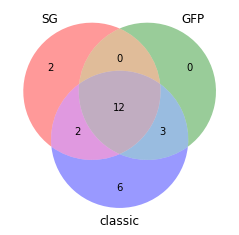

In [26]:
venn3_unweighted([set(prsrrs_v2[(prsrrs_v2.positive_SG==True )].pair),
       set(prsrrs_v2[(prsrrs_v2.positive_GFP==True )].pair),
       set(prsrrs_v2[(prsrrs_v2.positive_old==True )].pair)],['SG','GFP','classic'])
plt.savefig('venn3_gfp_sg_classic_vectors.pdf')

In [27]:
prsrrs_v2[(prsrrs_v2.positive_old==True )| (prsrrs_v2.positive_GFP==True) |  (prsrrs_v2.positive_SG==True)].sort_values(by=['positive_old','positive_GFP','positive_SG'])

,ad_ensg,ad_orf_id,db_ensg,db_orf_id,retest_type,plate,N2_source_well,uniprot_a,uniprot_b,N1_source_plate,N2_source_plate,pair,N1_source_well,YN2H_N1N2_XY,AB_GFP,AF2_GFP,BF1_GFP,AB_old,AF2_old,BF1_old,NLR_old,NLR_GFP,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
52,ENSG00000136937,7450,ENSG00000114503,2754,PRS,1,E09,Q09161,P52298-1,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(NCBP1, NCBP2)",E09,1.403326,1531,1078,103,1215,1195,96,1.016736,1.420223,True,False,False,0.023946,0.506117,0.488850
102,ENSG00000142208,5348,ENSG00000140992,9307,PRS,2,F06,P31749-1,O15530-4,yN2H_PRS_N1_2A,yN2H_PRS_N2_2B,"(AKT1, PDPK1)",F06,1.720351,433,563,316,728,625,357,1.164800,0.769094,True,False,False,0.220082,-0.378768,0.782703
14,ENSG00000159352,3169,ENSG00000179262,7058,PRS,1,E03,P55036-1,P54725-1,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(PSMD4, RAD23A)",E03,1.039870,1030,151,700,2589,137,584,4.433219,1.471429,False,True,False,2.148355,0.557218,0.056403
22,ENSG00000100644,6151,ENSG00000141510,3774,PRS,1,F04,Q16665-1,P04637-1,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(HIF1A, TP53)",F04,1.147541,213,96,172,240,110,117,2.051282,1.238372,False,True,False,1.036526,0.308445,0.198546
27,ENSG00000171223,4265,ENSG00000156127,9618,PRS,1,F05,P17275,Q16520,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(BATF, JUNB)",F05,0.984934,199,117,82,220,96,82,2.291667,1.700855,False,True,False,1.196397,0.766260,-0.021901
54,ENSG00000113558,6671,ENSG00000145604,4656,PRS,1,A10,P63208-1,Q13309-2,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(SKP1, SKP2)",A10,0.305768,254,151,89,247,144,89,1.715278,1.682119,False,True,False,0.778442,0.750280,-1.709489
86,ENSG00000160789,3903,ENSG00000139687,8208,PRS,2,B04,P02545-2,P06400,yN2H_PRS_N1_2A,yN2H_PRS_N2_2B,"(LMNA, RB1)",B04,0.219955,172,165,130,391,137,206,1.898058,1.042424,False,True,False,0.924524,0.059943,-2.184722
107,ENSG00000136238,4232,ENSG00000132254,3971,PRS,2,C08,P63000-1,P53365-1,yN2H_PRS_N1_2A,yN2H_PRS_N2_2B,"(ARFIP2, RAC1)",C08,0.252996,282,151,158,488,165,151,2.957576,1.784810,False,True,False,1.564415,0.835771,-1.982813
16,ENSG00000073111,4536,ENSG00000112118,3726,PRS,1,G03,P49736,P25205-1,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,"(MCM2, MCM3)",G03,2.001073,233,130,117,282,130,117,2.169231,1.792308,True,True,False,1.117184,0.841818,1.000774
73,ENSG00000160789,3903,ENSG00000113368,2370,PRS,2,A02,P02545-2,P20700,yN2H_PRS_N1_2A,yN2H_PRS_N2_2B,"(LMNA, LMNB1)",A02,12.882040,124,172,103,1758,130,172,10.220930,0.720930,True,True,False,3.353455,-0.472068,3.687289


In [28]:
col = ['ad_orf_id', 'db_orf_id', 'retest_type', 'plate',
       'N2_source_well', 'N1_source_plate', 'N2_source_plate', 
       'N1_source_well', 'pair','YN2H_N1N2_XY', 'AB_GFP', 'AF2_GFP', 'BF1_GFP',
       'AB_old', 'AF2_old', 'BF1_old', 'NLR_old', 'NLR_GFP', 'positive_SG',
       'positive_old', 'positive_GFP', 'NLR_old_log2', 'NLR_GFP_log2',
       'NLR_SG_log2']

prsrrs_v2[col].to_csv('yN2H_PRS_RRS_table.csv', sep='\t')


In [29]:
max(prsrrs_v2[prsrrs_v2.retest_type == 'RRS'].NLR_old), max(prsrrs_v2[prsrrs_v2.retest_type == 'RRS'].NLR_GFP)

(1.6231155778894473, 2.2554744525547443)

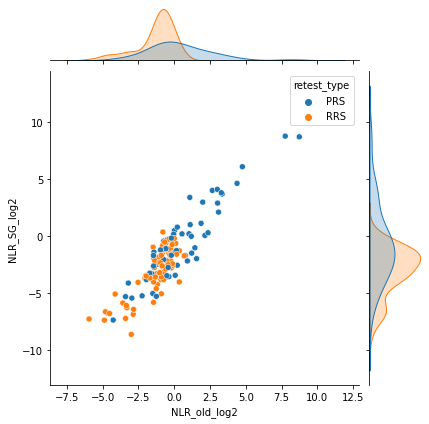

In [30]:
sns.jointplot(x='NLR_old_log2', y='NLR_SG_log2', data=prsrrs_v2, hue='retest_type')
plt.savefig('scatter_SG_old.pdf')

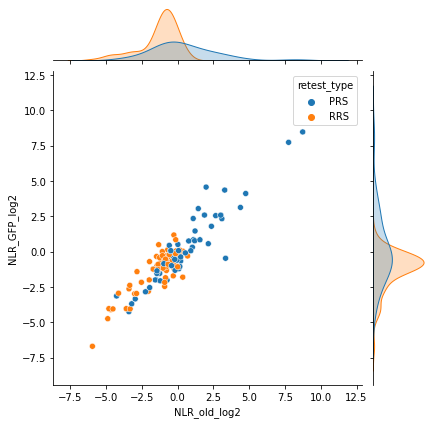

In [31]:
sns.jointplot(x='NLR_old_log2', y='NLR_GFP_log2', data=prsrrs_v2, hue='retest_type')
plt.savefig('scatter_GFP_old.pdf')

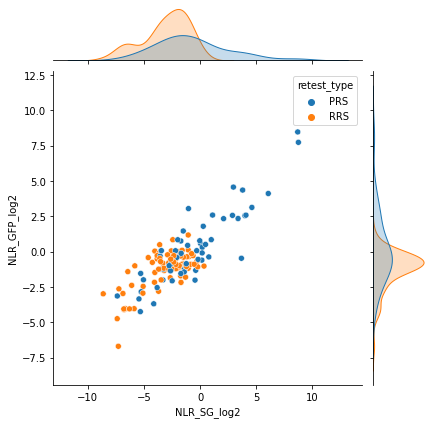

In [32]:
sns.jointplot(x='NLR_SG_log2', y='NLR_GFP_log2', data=prsrrs_v2, hue='retest_type')
plt.savefig('scatter_GFP_SG.pdf')

# upload data on vus.retest table

In [43]:
prsrrs = GetDF('n2h','prsrrs')

prsrrsv2 = prsrrs[(prsrrs.is_v2==True)].copy()

prsrrsv2['N1_source_plate'] = [f'yN2H_PRS_N1_{plate}A' for plate in prsrrsv2.plate]
prsrrsv2['N2_source_plate'] = [f'yN2H_PRS_N2_{plate}B' for plate in prsrrsv2.plate]

prsrrsv2.drop(columns=['comment_a', 'comment_b','entrez_gene_ida','symbol_a','entrez_gene_idb','symbol_b','is_binary','is_v2'], inplace=True)
prsrrsv2.rename(columns={'category':'retest_type','well':'N2_source_well','ensembl_gene_id_a':'ad_ensg', 'ensembl_gene_id_b':'db_ensg','orf_ida':'ad_orf_id', 'orf_idb':'db_orf_id'}, inplace=True)
prsrrsv2['pair'] = [tuple(sorted([orf_to_symbol[ad], orf_to_symbol[db]]))  for ad, db in zip(prsrrsv2.ad_orf_id, prsrrsv2.db_orf_id)]
prsrrsv2['N1_source_well'] = prsrrsv2.N2_source_well

for col_name in ['AB_GFP', 'AF2_GFP', 'BF1_GFP', 'AB_old', 'AF2_old', 'BF1_old']:
    
    prsrrsv2[col_name] = [res[col_name][(pla,well)] for pla, well in  zip(prsrrsv2.plate, prsrrsv2.N2_source_well)]

    

col = ['ad_orf_id', 'db_orf_id', 'retest_type', 'plate',
       'N2_source_plate','N2_source_well', 'N1_source_plate', 'N1_source_well', 'AB_GFP', 'AF2_GFP','BF1_GFP', 'AB_old', 'AF2_old', 'BF1_old']


prsrrsv2 = prsrrsv2[col].copy()

d = {a:b for a,b in zip(['AB_GFP', 'AF2_GFP', 'BF1_GFP', 'AB_old', 'AF2_old', 'BF1_old'],['N1N2_GFP', 'N1F2_GFP', 'N2F1_GFP', 'N1N2_old', 'N1F2_old', 'N2F1_old'])}
prsrrsv2.rename(columns = d, inplace=True)


prsrrsv2

,ad_orf_id,db_orf_id,retest_type,plate,N2_source_plate,N2_source_well,N1_source_plate,N1_source_well,N1N2_GFP,N1F2_GFP,N2F1_GFP,N1N2_old,N1F2_old,N2F1_old
0,1108,5001,PRS,1,yN2H_PRS_N2_1B,A01,yN2H_PRS_N1_1A,A01,8687,1161,1717,4319,948,2026
3,617,4447,RRS,1,yN2H_PRS_N2_1B,D01,yN2H_PRS_N1_1A,D01,110,89,247,82,76,220
5,3535,5887,RRS,1,yN2H_PRS_N2_1B,F01,yN2H_PRS_N1_1A,F01,1806,2246,261,2925,3090,185
6,3174,7186,RRS,1,yN2H_PRS_N2_1B,G01,yN2H_PRS_N1_1A,G01,103,721,103,144,591,69
8,273,5046,RRS,1,yN2H_PRS_N2_1B,A02,yN2H_PRS_N1_1A,A02,1476,1442,172,1600,1250,110
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178,4527,8732,RRS,2,yN2H_PRS_N2_2B,G11,yN2H_PRS_N1_2A,G11,151,247,130,76,295,89
179,2794,5808,PRS,2,yN2H_PRS_N2_2B,H11,yN2H_PRS_N1_2A,H11,199,103,76,185,206,82
180,2403,2391,PRS,2,yN2H_PRS_N2_2B,A12,yN2H_PRS_N1_2A,A12,179,357,137,288,385,144
181,3341,8297,RRS,2,yN2H_PRS_N2_2B,B12,yN2H_PRS_N1_2A,B12,776,2074,213,426,3035,137


In [69]:
col = ['ad_orf_id','db_orf_id','retest_type','plate','N2_source_plate','N2_source_well','N1_source_plate','N1_source_well','N2F1_GFP']

prsrrsv2_gfp_emptyN1 = prsrrsv2[col].copy()
prsrrsv2_gfp_emptyN1.rename(columns={'N2F1_GFP':'xp1'}, inplace=True)
prsrrsv2_gfp_emptyN1['N1_source_plate'] = prsrrsv2_gfp_emptyN1.N1_source_plate.apply(lambda x: f'yN2H_PRS_GFP_EN1_{x.split("_")[-1]}')
prsrrsv2_gfp_emptyN1['N2_source_plate'] = prsrrsv2_gfp_emptyN1.N2_source_plate.apply(lambda x: f'yN2H_PRS_GFP_N2_{x.split("_")[-1]}')
prsrrsv2_gfp_emptyN1['ad_orf_id'] = 0
prsrrsv2_gfp_emptyN1['standard_batch'] = 'hsPRSRRSv2_GFP'

col = ['ad_orf_id','db_orf_id','retest_type','plate','N2_source_plate','N2_source_well','N1_source_plate','N1_source_well','N1F2_GFP']

prsrrsv2_gfp_emptyN2 = prsrrsv2[col].copy()
prsrrsv2_gfp_emptyN2.rename(columns={'N1F2_GFP':'xp1'}, inplace=True)
prsrrsv2_gfp_emptyN2['N1_source_plate'] = prsrrsv2_gfp_emptyN2.N1_source_plate.apply(lambda x: f'yN2H_PRS_GFP_N1_{x.split("_")[-1]}')
prsrrsv2_gfp_emptyN2['N2_source_plate'] = prsrrsv2_gfp_emptyN2.N2_source_plate.apply(lambda x: f'yN2H_PRS_GFP_EN2_{x.split("_")[-1]}')
prsrrsv2_gfp_emptyN2['db_orf_id'] = 0
prsrrsv2_gfp_emptyN2['standard_batch'] = 'hsPRSRRSv2_GFP'

col = ['ad_orf_id','db_orf_id','retest_type','plate','N2_source_plate','N2_source_well','N1_source_plate','N1_source_well','N1N2_GFP']

prsrrsv2_gfp = prsrrsv2[col].copy()
prsrrsv2_gfp.rename(columns={'N1N2_GFP':'xp1'}, inplace=True)
prsrrsv2_gfp['N1_source_plate'] = prsrrsv2_gfp.N1_source_plate.apply(lambda x: f'yN2H_PRS_GFP_N1_{x.split("_")[-1]}')
prsrrsv2_gfp['N2_source_plate'] = prsrrsv2_gfp.N2_source_plate.apply(lambda x: f'yN2H_PRS_GFP_N2_{x.split("_")[-1]}')
prsrrsv2_gfp['standard_batch'] = 'hsPRSRRSv2_GFP'

########################################################

col = ['ad_orf_id','db_orf_id','retest_type','plate','N2_source_plate','N2_source_well','N1_source_plate','N1_source_well','N2F1_old']

prsrrsv2_old_emptyN1 = prsrrsv2[col].copy()
prsrrsv2_old_emptyN1.rename(columns={'N2F1_old':'xp1'}, inplace=True)
prsrrsv2_old_emptyN1['N1_source_plate'] = prsrrsv2_old_emptyN1.N1_source_plate.apply(lambda x: f'yN2H_PRS_old_EN1_{x.split("_")[-1]}')
prsrrsv2_old_emptyN1['N2_source_plate'] = prsrrsv2_old_emptyN1.N2_source_plate.apply(lambda x: f'yN2H_PRS_old_N2_{x.split("_")[-1]}')
prsrrsv2_old_emptyN1['ad_orf_id'] = 0
prsrrsv2_old_emptyN1['standard_batch'] = 'hsPRSRRSv2_old'

col = ['ad_orf_id','db_orf_id','retest_type','plate','N2_source_plate','N2_source_well','N1_source_plate','N1_source_well','N1F2_old']

prsrrsv2_old_emptyN2 = prsrrsv2[col].copy()
prsrrsv2_old_emptyN2.rename(columns={'N1F2_old':'xp1'}, inplace=True)
prsrrsv2_old_emptyN2['N1_source_plate'] = prsrrsv2_old_emptyN2.N1_source_plate.apply(lambda x: f'yN2H_PRS_old_N1_{x.split("_")[-1]}')
prsrrsv2_old_emptyN2['N2_source_plate'] = prsrrsv2_old_emptyN2.N2_source_plate.apply(lambda x: f'yN2H_PRS_old_EN2_{x.split("_")[-1]}')
prsrrsv2_old_emptyN2['db_orf_id'] = 0
prsrrsv2_old_emptyN2['standard_batch'] = 'hsPRSRRSv2_old'

col = ['ad_orf_id','db_orf_id','retest_type','plate','N2_source_plate','N2_source_well','N1_source_plate','N1_source_well','N1N2_old']

prsrrsv2_old = prsrrsv2[col].copy()
prsrrsv2_old.rename(columns={'N1N2_old':'xp1'}, inplace=True)
prsrrsv2_old['N1_source_plate'] = prsrrsv2_old.N1_source_plate.apply(lambda x: f'yN2H_PRS_old_N1_{x.split("_")[-1]}')
prsrrsv2_old['N2_source_plate'] = prsrrsv2_old.N2_source_plate.apply(lambda x: f'yN2H_PRS_old_N2_{x.split("_")[-1]}')
prsrrsv2_old['standard_batch'] = 'hsPRSRRSv2_old'


In [127]:
prsrrs_concat = pd.concat([prsrrsv2_gfp_emptyN1,prsrrsv2_gfp_emptyN2,prsrrsv2_gfp,prsrrsv2_old_emptyN1,prsrrsv2_old_emptyN2,prsrrsv2_old])
prsrrs_concat.rename(columns={'plate':'retest_pla', 'N2_source_plate':'db_source_plate', 'N1_source_plate':'ad_source_plate',
                              'N2_source_well':'db_source_well', 'N1_source_well':'ad_source_well', 'xp1':'N2H_raw_r01'
                             }
                     , inplace=True)
prsrrs_concat['retest_pos'] = prsrrs_concat.db_source_well
prsrrs_concat['retest_batch'] = prsrrs_concat.standard_batch
prsrrs_concat['variant_id'] = ['empty_N1' if n1 == 0 else 'empty_N2' if n2 == 0 else 'N1N2' for n1,n2 in zip(prsrrs_concat.ad_orf_id, prsrrs_concat.db_orf_id)]

prsrrs_concat.head()

,ad_orf_id,db_orf_id,retest_type,retest_pla,db_source_plate,db_source_well,ad_source_plate,ad_source_well,N2H_raw_r01,standard_batch,retest_pos,retest_batch,variant_id
0,0,5001,PRS,1,yN2H_PRS_GFP_N2_1B,A01,yN2H_PRS_GFP_EN1_1A,A01,1717,hsPRSRRSv2_GFP,A01,hsPRSRRSv2_GFP,empty_N1
3,0,4447,RRS,1,yN2H_PRS_GFP_N2_1B,D01,yN2H_PRS_GFP_EN1_1A,D01,247,hsPRSRRSv2_GFP,D01,hsPRSRRSv2_GFP,empty_N1
5,0,5887,RRS,1,yN2H_PRS_GFP_N2_1B,F01,yN2H_PRS_GFP_EN1_1A,F01,261,hsPRSRRSv2_GFP,F01,hsPRSRRSv2_GFP,empty_N1
6,0,7186,RRS,1,yN2H_PRS_GFP_N2_1B,G01,yN2H_PRS_GFP_EN1_1A,G01,103,hsPRSRRSv2_GFP,G01,hsPRSRRSv2_GFP,empty_N1
8,0,5046,RRS,1,yN2H_PRS_GFP_N2_1B,A02,yN2H_PRS_GFP_EN1_1A,A02,172,hsPRSRRSv2_GFP,A02,hsPRSRRSv2_GFP,empty_N1


In [128]:
uploading_cols = ['ad_source_plate', 'ad_source_well',
       'db_source_plate', 'db_source_well', 'ad_orf_id',
       'db_orf_id', 'retest_pla', 'variant_id','retest_batch','standard_batch',
       'retest_pos','N2H_raw_r01']

df = prsrrs_concat[uploading_cols].copy()

df.head()

,ad_source_plate,ad_source_well,db_source_plate,db_source_well,ad_orf_id,db_orf_id,retest_pla,variant_id,retest_batch,standard_batch,retest_pos,N2H_raw_r01
0,yN2H_PRS_GFP_EN1_1A,A01,yN2H_PRS_GFP_N2_1B,A01,0,5001,1,empty_N1,hsPRSRRSv2_GFP,hsPRSRRSv2_GFP,A01,1717
3,yN2H_PRS_GFP_EN1_1A,D01,yN2H_PRS_GFP_N2_1B,D01,0,4447,1,empty_N1,hsPRSRRSv2_GFP,hsPRSRRSv2_GFP,D01,247
5,yN2H_PRS_GFP_EN1_1A,F01,yN2H_PRS_GFP_N2_1B,F01,0,5887,1,empty_N1,hsPRSRRSv2_GFP,hsPRSRRSv2_GFP,F01,261
6,yN2H_PRS_GFP_EN1_1A,G01,yN2H_PRS_GFP_N2_1B,G01,0,7186,1,empty_N1,hsPRSRRSv2_GFP,hsPRSRRSv2_GFP,G01,103
8,yN2H_PRS_GFP_EN1_1A,A02,yN2H_PRS_GFP_N2_1B,A02,0,5046,1,empty_N1,hsPRSRRSv2_GFP,hsPRSRRSv2_GFP,A02,172


In [129]:
#fill_table_v2(uploading_cols, 'vus', 'retest', df)

0 828
0 828
0 828
0 828
0 828
0 828
